# One block, one pass, or six passes?

In chapter 3, each transformer block had its own weights. Here we ask whether
we can reuse one block instead of storing six of them. We will build and train
just three models:

| Model | What happens to the image tokens? |
| --- | --- |
| Six-block ViT | Six separate blocks process the tokens in order. |
| One-block ViT | One block processes the tokens once. |
| Looped ViT | One shared block processes the updated tokens six times. |

Every model makes one final prediction and learns from the correct image label.
The one-block model is trained separately, not taken from the first pass of
the looped model. All three use the same image embedding and classifier design.
Their weights are learned separately.

You can read the code and the reference results without training anything.
Running all cells downloads CIFAR-100 and trains the three models. A GPU is
recommended for the full run. The final table will contain your measured
results, which need not match the reference scores exactly.

## 1. Set up the notebook

The notebook uses PyTorch, torchvision, matplotlib, and IPython. If they are
missing, install them with `%pip install torch torchvision matplotlib ipython`
in a separate cell. The first cell selects a GPU when one is available.

In [ ]:
import hashlib
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Device:", device)

Keep these settings the same for all three models. Each 32 by 32 image becomes
sixty-four 4 by 4 patches. We use the same token width and training recipe so
the main difference is how the transformer blocks are arranged.

For a quick check that the notebook runs, set `EPOCHS = 2` and
`TRAIN_SUBSET = 512`. Those settings test the workflow; they are not enough to
judge model accuracy. The full settings below match the chapter's comparison.

In [ ]:
SEED = 42
IMG_SIZE = 32
PATCH_SIZE = 4
CHANNELS = 3
CLASSES = 100
EMBED_DIM = 192
HEADS = 3
MLP_RATIO = 4
DEPTH = 6
BATCH_SIZE = 128
EPOCHS = 60
LR = 1e-3
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
VAL_SIZE = 5000
TRAIN_SUBSET = None
NUM_WORKERS = 0
CHECKPOINT_DIR = Path("./checkpoints_three_models")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

## 2. Prepare the images

CIFAR-100 contains small color images in one hundred classes. We reserve 5,000
training images for validation, leaving 45,000 for learning the weights. The
separate test set is used after training. Every model gets the same split.

The training transform changes images slightly so the models have more than
one view to learn from. Validation and test images are only converted to
tensors and normalized. These transforms stay the same across the three models.

The picture below shows how the images are divided.

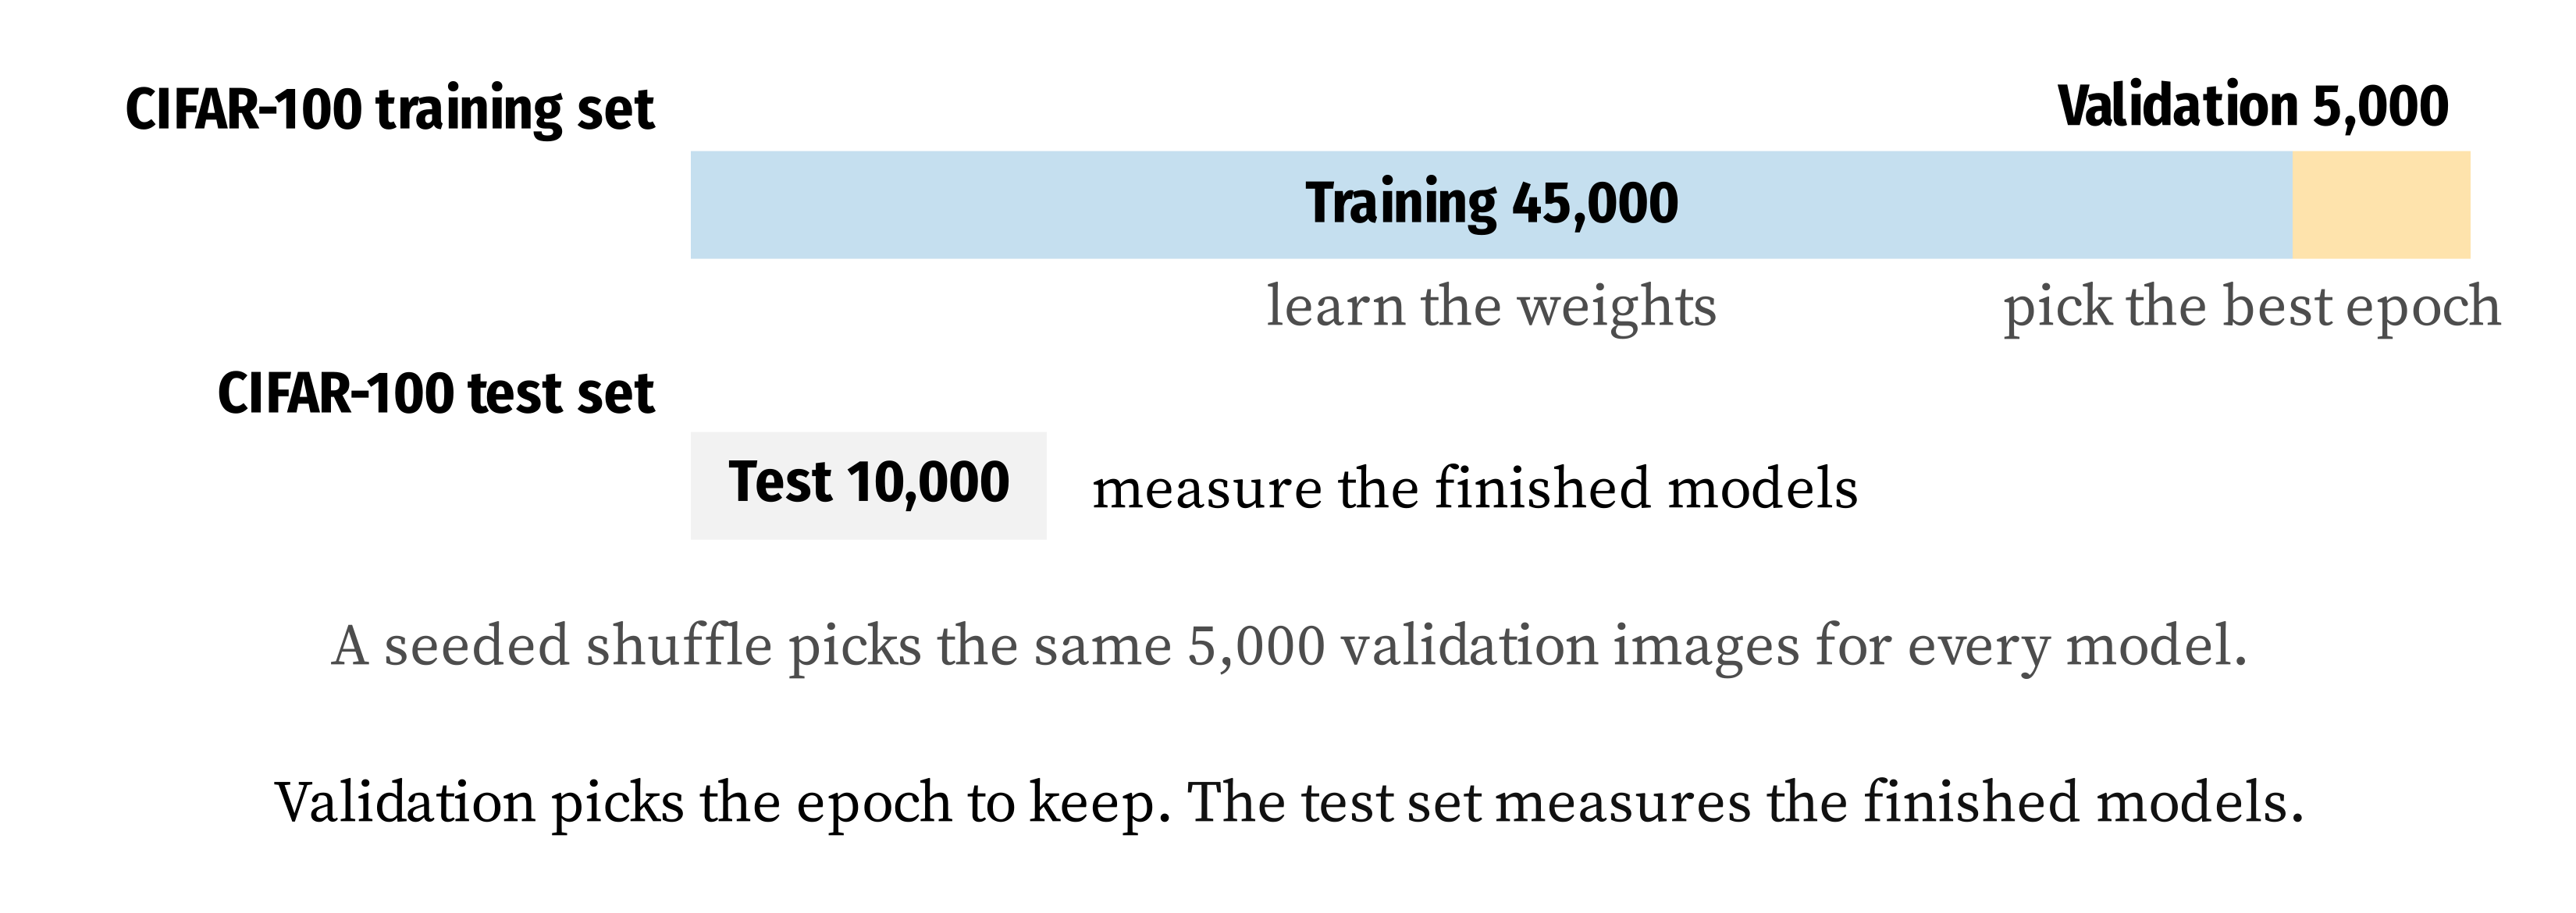

*Training, validation, and test images have different jobs. All three models use the same split.*

The training images are used to update the weights. After each epoch, the validation images help us decide which version of those weights to keep. The test images are kept separate until we evaluate the finished models. These counts describe the full run, not the small subset used for a quick code check.

In [ ]:
mean = (0.5071, 0.4865, 0.4409)
std = (0.2673, 0.2564, 0.2762)
train_tfm = transforms.Compose([
    transforms.RandomCrop(IMG_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),
])
eval_tfm = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(mean, std)
])
train_full = datasets.CIFAR100(
    "./data", train=True, download=True, transform=train_tfm
)
val_full = datasets.CIFAR100(
    "./data", train=True, download=True, transform=eval_tfm
)
test = datasets.CIFAR100(
    "./data", train=False, download=True, transform=eval_tfm
)
class_names = test.classes

perm = torch.randperm(
    len(train_full), generator=torch.Generator().manual_seed(SEED)
)
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
if TRAIN_SUBSET is not None:
    train_idx = train_idx[:TRAIN_SUBSET]
train = Subset(train_full, train_idx.tolist())
val = Subset(val_full, val_idx.tolist())
if len(train) < BATCH_SIZE:
    raise ValueError("Use at least one full training batch.")
loader_args = dict(
    num_workers=NUM_WORKERS, pin_memory=(device == "cuda")
)
train_dl = DataLoader(
    train, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_args
)
val_dl = DataLoader(val, batch_size=256, **loader_args)
test_dl = DataLoader(test, batch_size=256, **loader_args)
print(f"Images: {len(train)} train, {len(val)} validation, {len(test)} test")

## 3. Reuse the familiar ViT components

Each model needs the same start and finish: turn image patches into tokens,
add the class token and positions, then read the final class token to classify
the image. `ViTBase` puts those common parts in one place. The blocks in the
middle will differ.

With the default settings, `embed` returns 65 tokens, each with 192 features.
`classify` reads the class token and returns 100 class scores per image.

The picture below follows one image through the parts that every model shares.

![A left-to-right flow: an image goes through PatchEmbed, a class token is prepended, positions are added, then transformer blocks process the tokens. The final class token is normalized and a linear head produces 100 class scores. The first three steps are labelled embed(images), giving 65 tokens of 192 features. The last two are labelled classify(x). The blocks are six blocks, one block, or one shared block used six times.](attachment:NB_LV02_Common_Components.png)

*All three models use the same input and output design. The block arrangement in the middle changes, and each model learns its own weights.*

The image first becomes 64 patch tokens. We add the class token and position information before the transformer processes them. At the end, the classifier reads the final class token and produces one score for each of the 100 classes. The next cells change the processing in the middle while keeping this start and finish consistent.
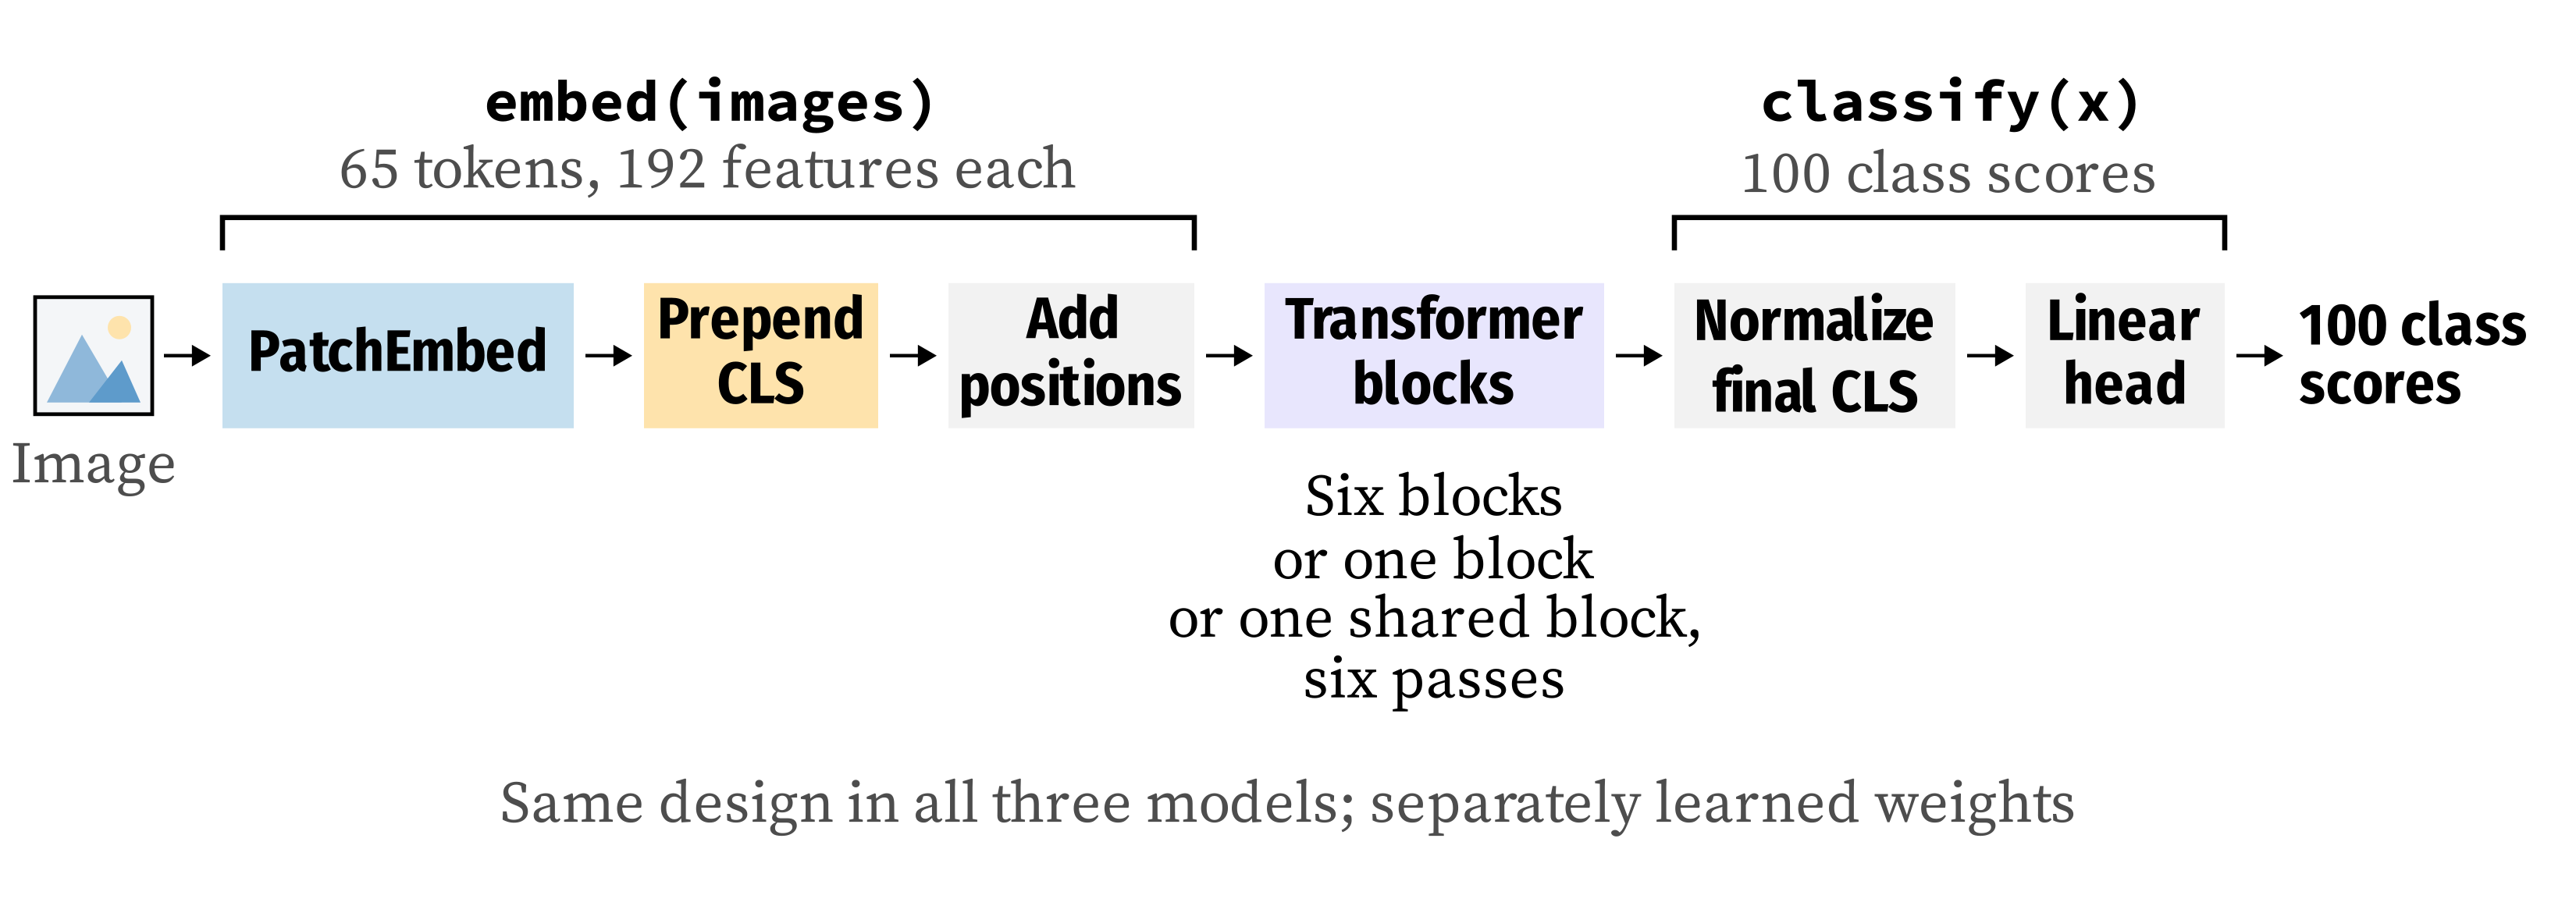

In [ ]:
class PatchEmbed(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(CHANNELS, EMBED_DIM, PATCH_SIZE, PATCH_SIZE)
        self.n = (IMG_SIZE // PATCH_SIZE) ** 2

    def forward(self, images):
        return self.proj(images).flatten(2).transpose(1, 2)

def make_block():
    return nn.TransformerEncoderLayer(
        EMBED_DIM, HEADS, EMBED_DIM * MLP_RATIO, dropout=0.0,
        activation="gelu", batch_first=True, norm_first=True
    )

class ViTBase(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbed()
        self.cls = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        self.pos = nn.Parameter(
            torch.randn(1, self.patch.n + 1, EMBED_DIM) * 0.02
        )
        self.norm = nn.LayerNorm(EMBED_DIM)
        self.head = nn.Linear(EMBED_DIM, CLASSES)

    def embed(self, images):
        x = self.patch(images)
        cls = self.cls.expand(x.shape[0], -1, -1)
        return torch.cat([cls, x], dim=1) + self.pos

    def classify(self, x):
        return self.head(self.norm(x[:, 0]))

## 4. Build the three models

Start with the ordinary stack. Each call to `make_block` creates a separate
set of weights. Setting `depth=6` gives the six-block model. Setting `depth=1`
gives the one-block model. Both read the class token only after their last block.

Before the code, the picture below puts the three models side by side.

![Three columns, each read from bottom to top. Left, six-block ViT: image embedding, six different blocks A to F, classifier, final prediction; 2.71 million parameters. Middle, one-block ViT: image embedding, block G, classifier, final prediction; 0.49 million parameters. Right, looped ViT: image embedding, one shared block R with a return arrow labelled next pass uses updated tokens, six passes, then the classifier and final prediction; 0.49 million parameters.](attachment:NB_LV03_Three_Models.png)

*Three models process the same kind of input. The six-block model stores six blocks, the one-block model uses one block once, and the looped model reuses one block six times.*

Read each column from the bottom up. On the left, each block has its own weights. The middle model stops after one block. On the right, the tokens return to the same block for another pass. This saves stored block weights, but the model still performs six block computations before making a prediction. The parameter totals include the image embedding and classifier, not just the transformer blocks.
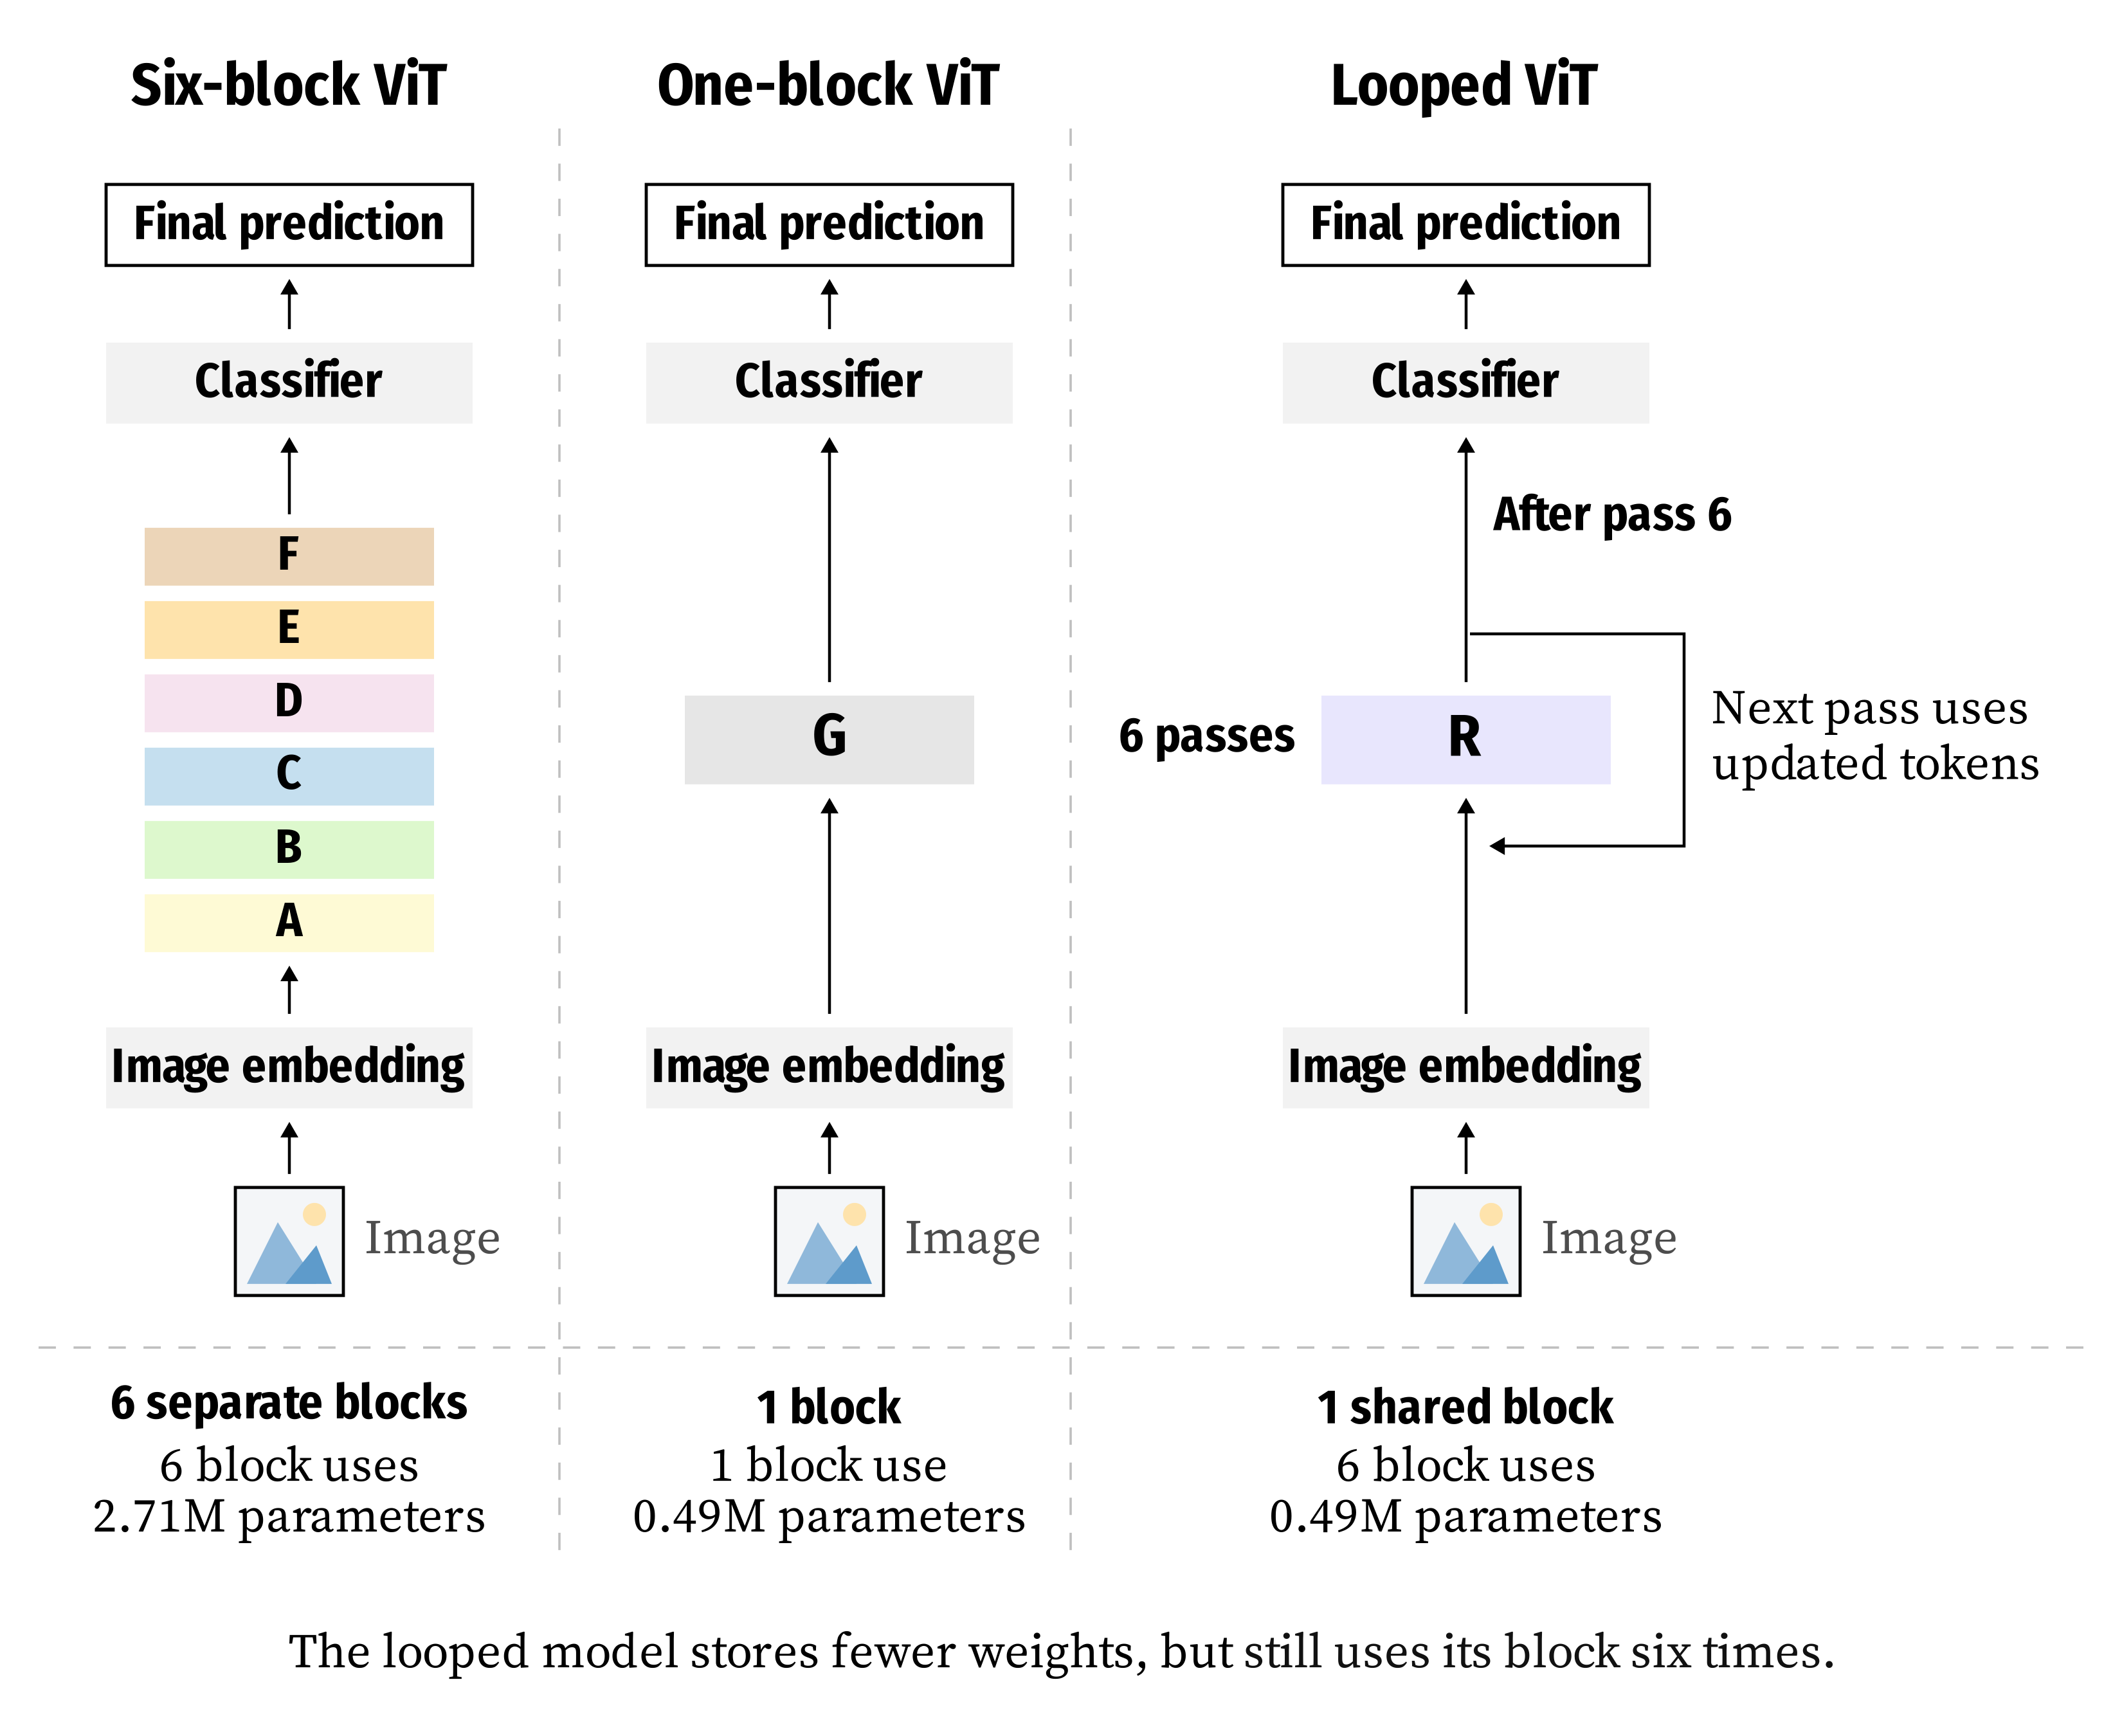

In [ ]:
class StackedViT(ViTBase):
    def __init__(self, depth=DEPTH):
        super().__init__()
        # Create separate blocks, each with its own learned weights.
        self.blocks = nn.ModuleList([
            make_block() for _ in range(depth)
        ])

    def forward(self, images):
        x = self.embed(images)
        for block in self.blocks:
            x = block(x)
        return self.classify(x)

The looped version creates just one block. After a pass, its output becomes
the input to the next pass. The weights stay the same; the token features change.

The picture below follows the tokens through the first two passes.

![Two rows. In pass 1, initial tokens go through shared block R and come out as updated tokens. An arrow carries these updated tokens into pass 2, where the same block R updates them again. A dashed arrow continues to pass 6, then a classifier makes the final prediction. A label says the weights are the same across passes.](attachment:NB_LV04_Updated_Tokens.png)

*The next pass starts from the previous pass's output. The token features change while the block weights are reused.*

Follow the arrow from the top row to the bottom row. It carries the updated tokens into the next pass. The shared block therefore receives a different input, even though its weights have not changed between passes. Training still learns those weights. We only mean that one forward pass reuses them instead of switching to a separate block. The step vector is left out of this overview and is shown separately beside the code.
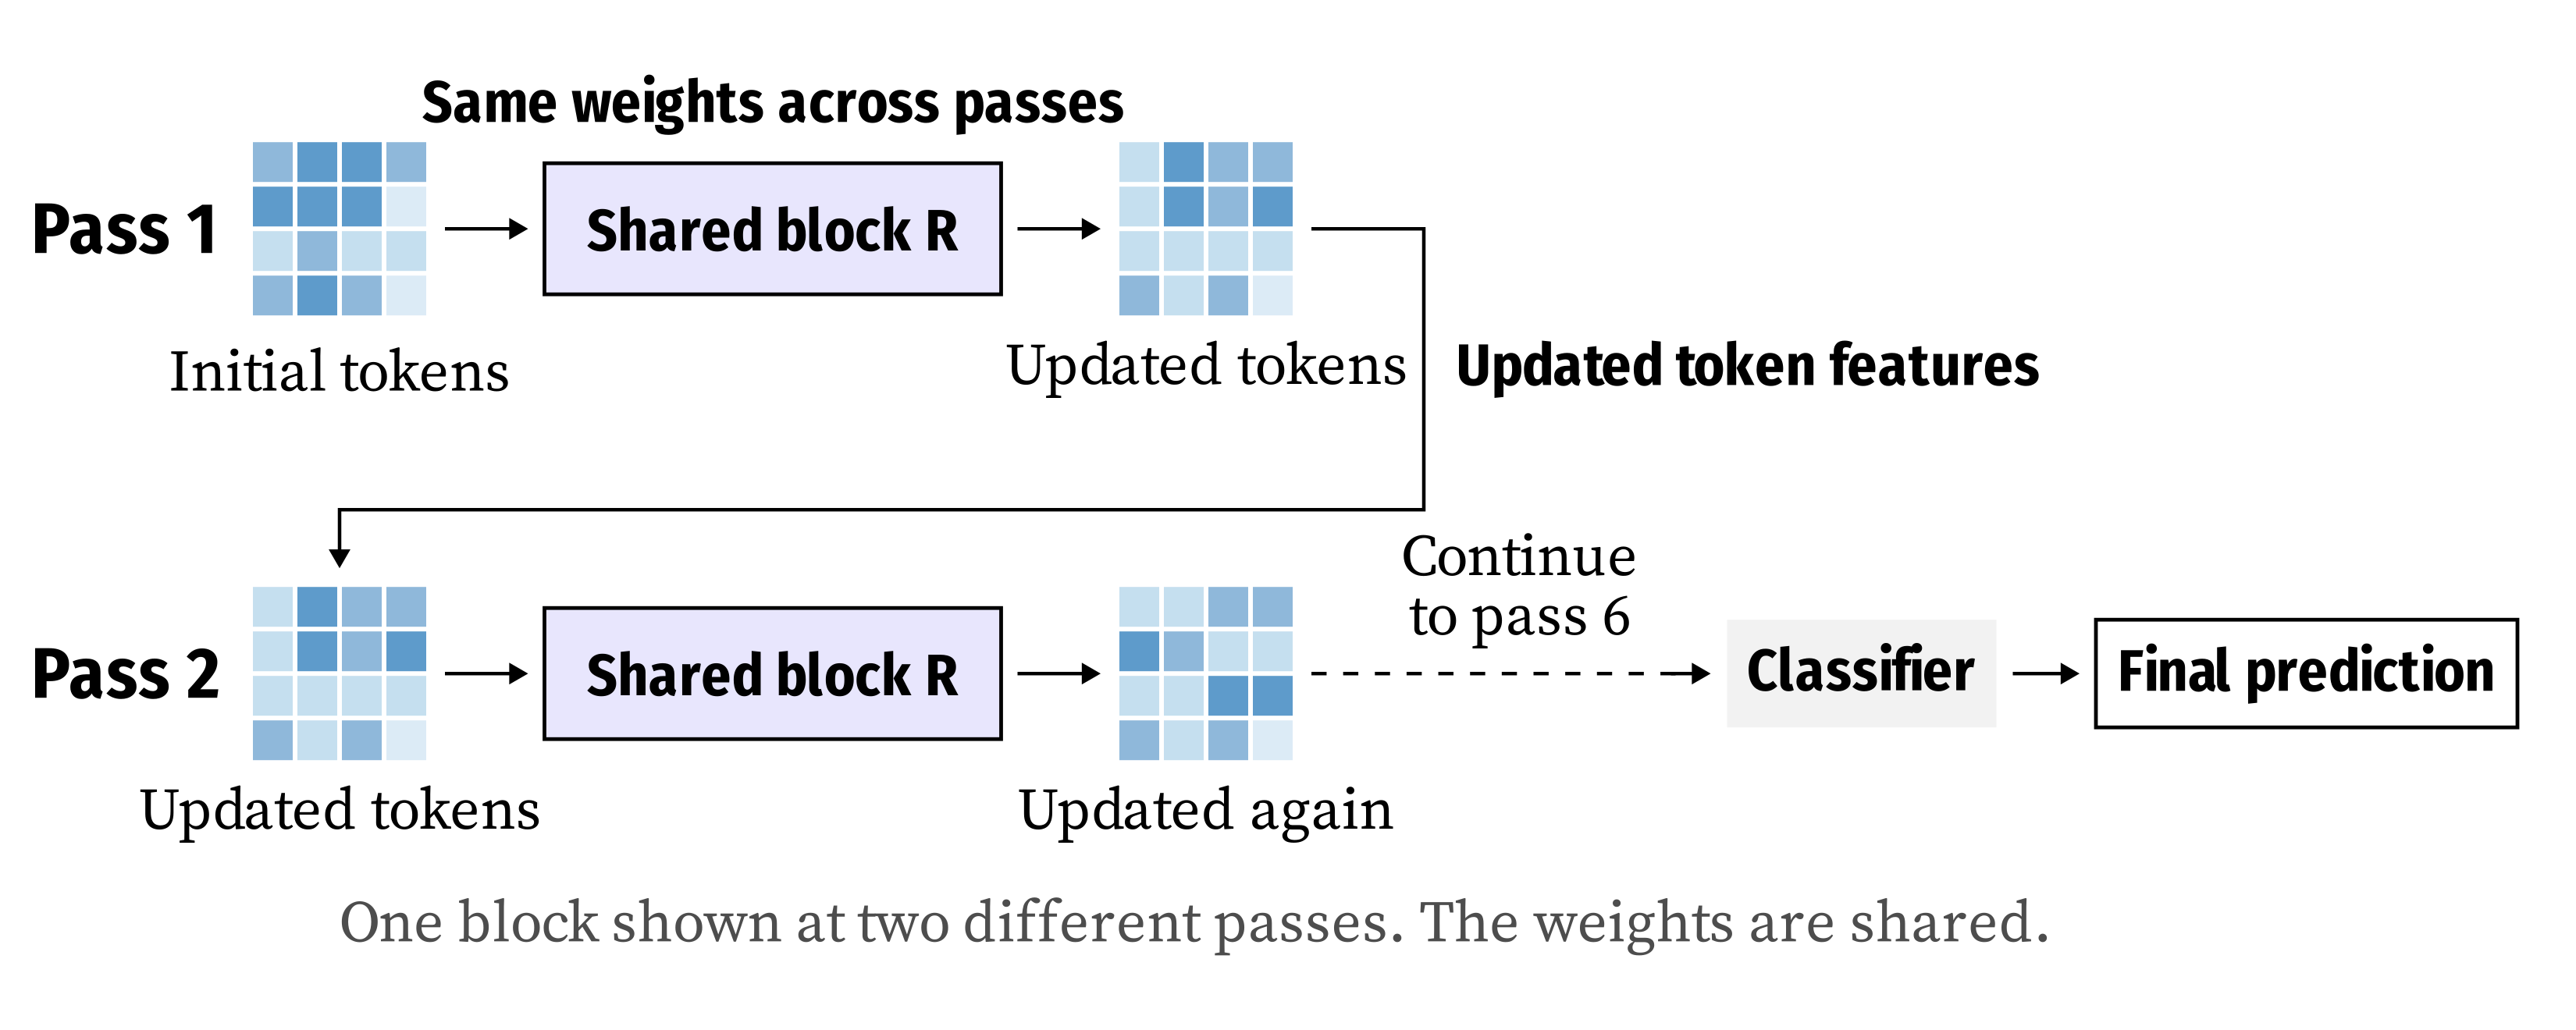

Before each pass, we add a small learned step vector to the tokens. There is
one vector per pass, which lets the shared block respond differently at each
step. This keeps the model used in the original comparison. The vectors start
at zero and are learned with the other parameters.

In [ ]:
class LoopedViT(ViTBase):
    def __init__(self, loops=DEPTH):
        super().__init__()
        self.loops = loops
        # Create one block and reuse it on every pass.
        self.block = make_block()
        self.step = nn.Parameter(
            torch.zeros(loops, 1, 1, EMBED_DIM)
        )

    def forward(self, images):
        x = self.embed(images)
        for t in range(self.loops):
            # Add this pass's vector, then update the tokens with the same block.
            x = self.block(x + self.step[t])
        # Make one prediction after the final pass.
        return self.classify(x)

Here is what the line inside the loop does on a single pass.

![A schematic of one pass. A grid of current tokens, with the class token in the first row, meets a plus sign. Above the plus is the vector for this pass, self.step[t], with 192 values. The result is a grid of the same size in which the same vector has been added to every token. It goes through shared block R, which has the same weights in every pass, and comes out as updated tokens for the next pass. A note says pass 1 uses self.step[0] and pass 6 uses self.step[5].](attachment:NB_LV05_Step_Vector.png)

*Before each pass, the model adds a small learned vector to the current tokens, then runs the shared block. Adding the vector does not add another token.*

The loop uses `t` to select one vector for the current pass. That vector is added to each token before the tokens enter the shared block. This gives the block a pass-specific input adjustment while it keeps the same weights. There are only six of these small vectors. The transformer block is still stored once.
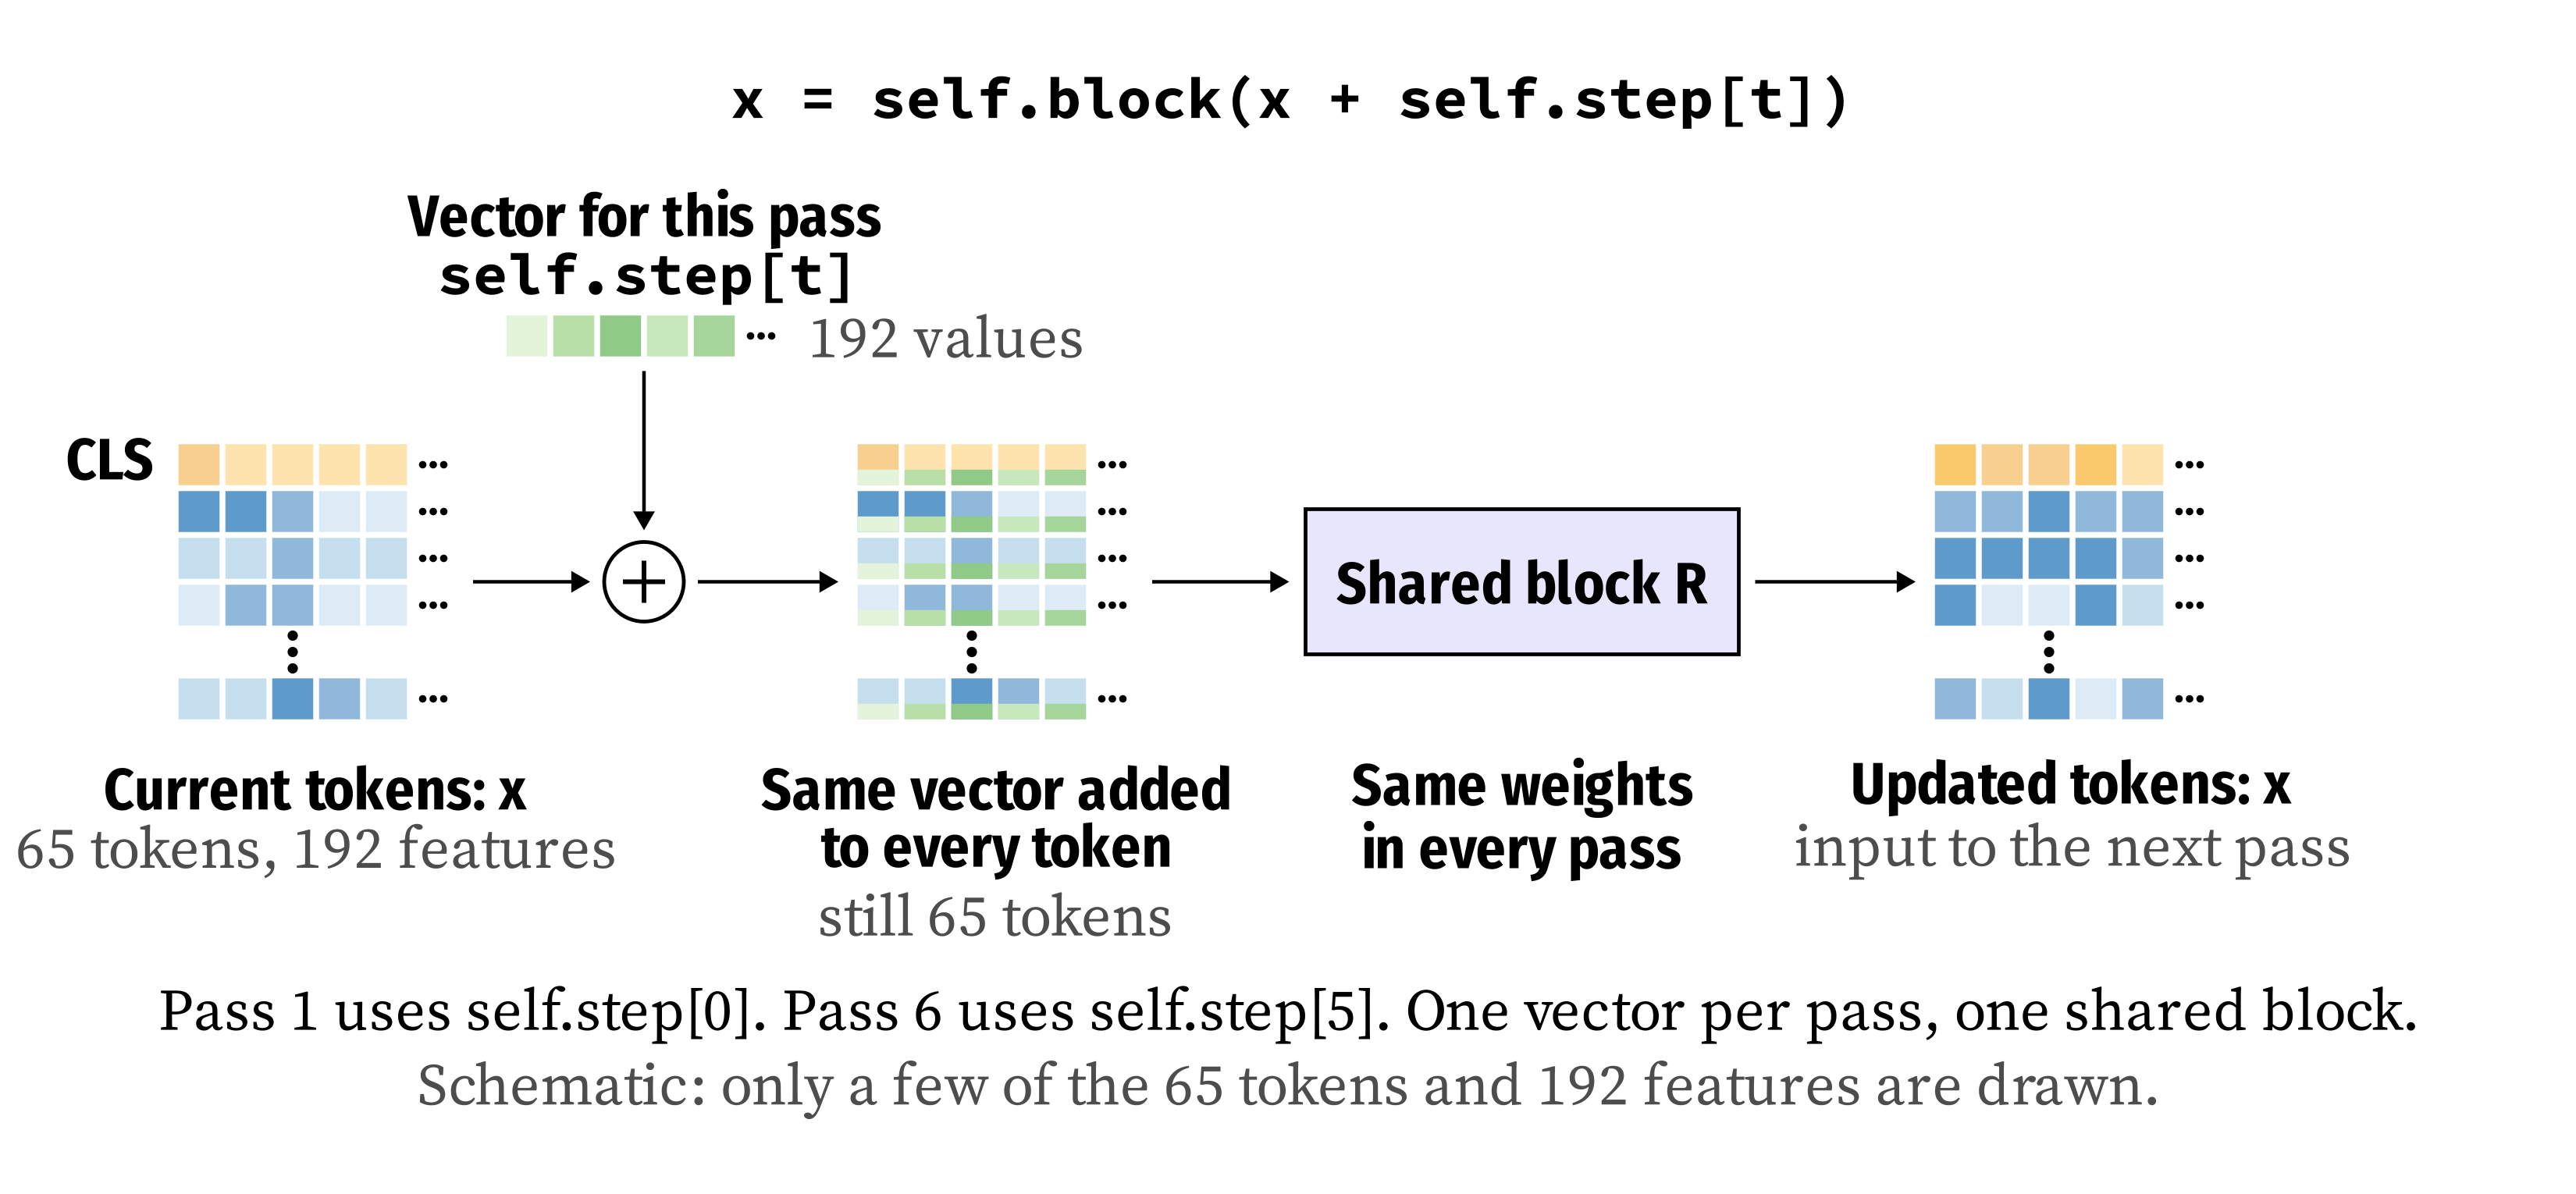

We now have everything needed for the comparison. This dictionary contains
exactly three constructors. A constructor creates a fresh model when called.

In [ ]:
MODEL_SPECS = {
    "Six-block ViT": (lambda: StackedViT(DEPTH), DEPTH),
    "One-block ViT": (lambda: StackedViT(1), 1),
    "Looped ViT": (lambda: LoopedViT(DEPTH), DEPTH),
}

In [ ]:
images = torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE)
for name, (make_model, block_uses) in MODEL_SPECS.items():
    model = make_model().eval()
    with torch.no_grad():
        scores = model(images)
    parameters = sum(p.numel() for p in model.parameters())
    print(f"{name}: {tuple(scores.shape)}, {parameters:,} parameters, "
          f"{block_uses} block uses")

Each output should have shape `(2, 100)`: one hundred class scores for each of
two images. The six-block model stores about 2.71 million parameters. The
other two store about 0.49 million each. Their exact counts differ slightly
because the looped model also has its step vectors.

## 5. Train the final prediction

All three models use the same loss. We compare their final class scores with
the image label. The code retains label smoothing of 0.1 from the training
recipe: a small part of the target probability is assigned to the other classes.
There is no separate training rule for the looped model.

In [ ]:
def classification_loss(model, images, labels):
    scores = model(images)
    return F.cross_entropy(
        scores, labels, label_smoothing=LABEL_SMOOTHING
    )

The next helpers run the usual training loop. After each epoch, we check the
validation images and keep the weights with the best validation accuracy.
The test images are not used to choose those weights.

The CUDA-specific lines use mixed precision when training on an NVIDIA GPU.
On other devices, training uses ordinary floating-point operations. These
settings are shared by all three models.

In [ ]:
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
    if total == 0:
        raise ValueError("The evaluation loader is empty.")
    return 100 * correct / total

def train_model(model, name):
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LR, total_steps=EPOCHS * len(train_dl),
        pct_start=0.1
    )
    use_amp = device == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_accuracy, best_state = -1.0, None
    for epoch in range(EPOCHS):
        model.train()
        for images, labels in train_dl:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                "cuda", dtype=torch.float16, enabled=use_amp
            ):
                loss = classification_loss(model, images, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        val_accuracy = accuracy(model, val_dl)
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
        print(f"{name}: epoch {epoch + 1}/{EPOCHS}, "
              f"validation accuracy {val_accuracy:.1f}%")
    if best_state is None:
        raise ValueError("Use at least one training epoch.")
    model.load_state_dict(best_state)

## 6. Run the three-model comparison

The checkpoint helper saves completed models so you do not have to train them
again when reopening the notebook. It puts this project in its own folder and
includes the model name, seed, and training settings in the checkpoint identity.
Changing those settings creates a different filename. Keep old checkpoints;
there is no need to delete them.

Run the training cell only when you are ready to train all three models. Full
training takes much longer than the shape check. A quick-check subset is useful
for testing the code, but its accuracy should not be compared with the full run.

In [ ]:
def checkpoint_config(name):
    return {
        "recipe": "three_models_final_prediction_v1",
        "model": name, "dataset": "cifar100", "seed": SEED,
        "image_size": IMG_SIZE, "patch_size": PATCH_SIZE,
        "classes": CLASSES, "dim": EMBED_DIM, "heads": HEADS,
        "mlp_ratio": MLP_RATIO, "depth": DEPTH,
        "batch_size": BATCH_SIZE, "epochs": EPOCHS,
        "lr": LR, "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,
        "validation_size": VAL_SIZE, "train_subset": TRAIN_SUBSET,
        "workers": NUM_WORKERS,
        "augmentation": "crop_flip_trivialaugment_erasing_0.25",
        "torch": str(torch.__version__),
        "device": device,
    }

def run_model(name, make_model):
    seed_everything(SEED)
    model = make_model().to(device)
    config = checkpoint_config(name)
    signature = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()[:16]
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    path = CHECKPOINT_DIR / f"{safe_name}_{signature}.pt"
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=True)
        if saved["config"] != config:
            raise ValueError("Checkpoint settings do not match this run.")
        model.load_state_dict(saved["state"])
        print(f"{name}: loaded completed training")
    else:
        train_model(model, name)
        CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
        state = {key: value.detach().cpu()
                 for key, value in model.state_dict().items()}
        torch.save({"config": config, "state": state}, path)
    return model.eval()

In [ ]:
models = {}
for name, (make_model, block_uses) in MODEL_SPECS.items():
    models[name] = run_model(name, make_model)

## 7. Read your results

The next cell evaluates the three trained models on the test images. Read the
table across each row: how many parameters does the model store, how many
times does it use a block, and how often is its final prediction correct?
A block use is a processing step, not a measurement of time.

In [ ]:
rows = []
for name, (_, block_uses) in MODEL_SPECS.items():
    model = models[name]
    parameters = sum(p.numel() for p in model.parameters())
    test_accuracy = accuracy(model, test_dl)
    rows.append((name, parameters, block_uses, test_accuracy))

table = [
    "| Model | Parameters | Block uses per image | Test accuracy |",
    "| --- | ---: | ---: | ---: |",
]
for name, parameters, block_uses, test_accuracy in rows:
    table.append(
        f"| {name} | {parameters / 1e6:.2f} million | "
        f"{block_uses} | {test_accuracy:.1f}% |"
    )
display(Markdown("\n".join(table)))

### Reference results from the chapter

The table above is computed from your models. The following table is a reading
reference, using the earlier chapter results averaged over five training runs.
It is not output from a new execution of this revised notebook. Small changes
in the seed, device, or software can change your results.

| Model | Parameters | Block uses per image | Test accuracy |
| --- | ---: | ---: | ---: |
| Six-block ViT | 2.71 million | 6 | 58.5% |
| One-block ViT | 0.49 million | 1 | 31.0% |
| Looped ViT | 0.49 million | 6 | 55.5% |

The one-block model is small, but loses a lot of accuracy. Reusing a block gives
the small model more processing steps and brings its accuracy closer to the
six-block ViT. It still falls short, while storing far fewer parameters.

That is the trade-off to notice. The looped model runs a block six times, just
as the six-block model does. It saves stored weights, not six times the work.
These results do not show that it is automatically faster.

## 8. Look at one image together

A table summarizes thousands of images. Finish by looking at one image and
the three models' final labels. Change `IMAGE_INDEX` to inspect another example.
Some images will get the same answer from all three models; others will not.
A single example helps you inspect behavior, but does not replace test accuracy.

The picture below shows one saved example from the completed run. Set `IMAGE_INDEX = 3` in the next cell to look at the same image.

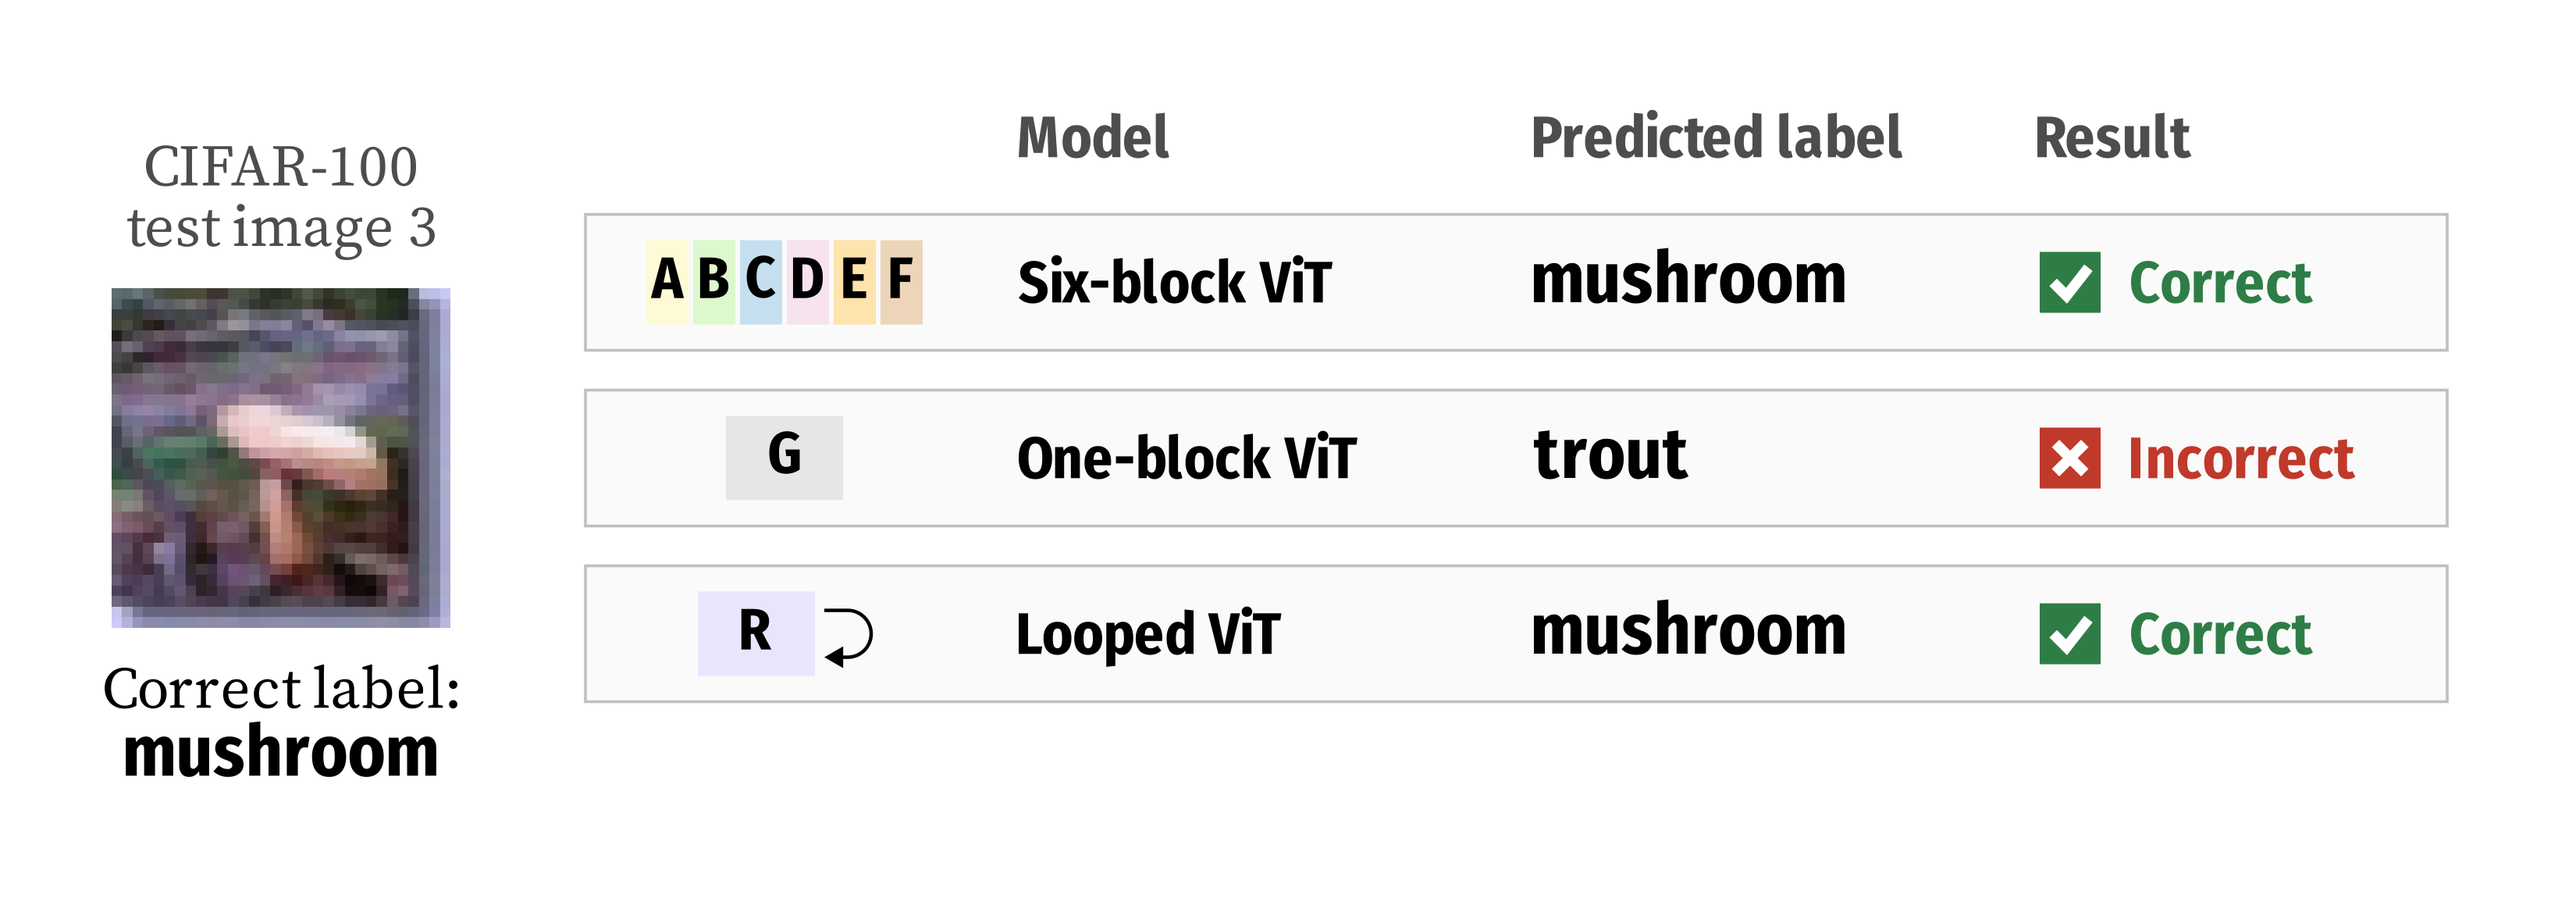

*On this test image, the six-block and looped models predict mushroom. The one-block model predicts trout. These are saved predictions from the completed run.*

This image was selected after training: it is the first test image where the six-block and looped models are correct and the one-block model is wrong. It lets us inspect one difference between their answers, but it does not establish which model is generally better. Use the full test-set results for that comparison, then inspect other images, including mistakes. If you train the models yourself, your labels for this image may differ.

In [ ]:
IMAGE_INDEX = 0
image_tensor, label = test[IMAGE_INDEX]
picture = image_tensor * torch.tensor(std)[:, None, None]
picture = picture + torch.tensor(mean)[:, None, None]
plt.figure(figsize=(3, 3))
plt.imshow(picture.permute(1, 2, 0).clamp(0, 1))
plt.title(f"Correct label: {class_names[label]}")
plt.axis("off")
plt.show()
with torch.no_grad():
    for name, model in models.items():
        model.eval()
        prediction = model(image_tensor[None].to(device)).argmax(1).item()
        print(f"{name}: {class_names[prediction]}")

## What to take away

The six-block model learns a different transformation at each step. The
one-block model has less capacity and only one processing step. The looped
model keeps a small set of block weights but uses them repeatedly on changing
token features. In this comparison, that recovers much of the accuracy lost
by the one-block model.

You have now built the three models, trained each from its final prediction,
compared their size and accuracy, and inspected their answers on an image.
When storage is tight, this is a useful alternative to simply removing blocks.